<a href="https://colab.research.google.com/github/nathannguyen13/A05-pca/blob/main/notebook_(5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [5]:
import pickle

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nathan Nguyen

**Date:** 10/21/2026

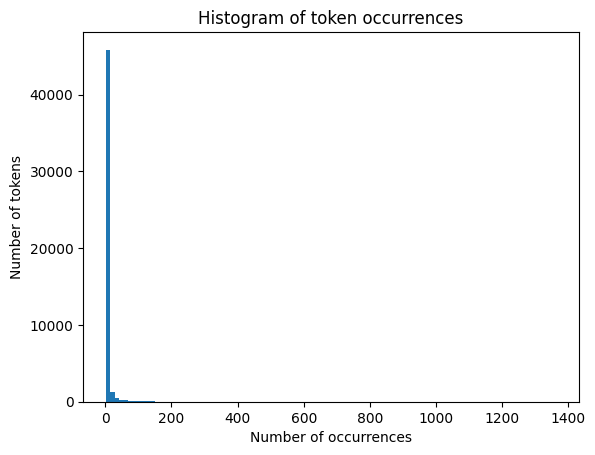

In [8]:
# Your Phase 1 solution to the problem goes here.

#Q1
import matplotlib.pyplot as plt

counts = [count for token, count in token_freq]

plt.hist(counts, bins=100)
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.title('Histogram of token occurrences')
plt.show()

The distribution is extremely right-skewed. Most tokens are rare: about 60% appear only once. A few common words, like “new,” “date,” and “please,” appear over a thousand times. The histogram looks like a tall spike near zero with a long, thin tail to the right, the typical Zipf’s law pattern in language.

In [10]:
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')
y = df['Email Type']; X = df.drop(columns='Email Type')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)

reg = LinearRegression().fit(X_train, y_train)
print(reg.score(X_train, y_train), reg.score(X_test, y_test))

coef = pd.Series(reg.coef_, index=X.columns)
coef[coef.abs().sort_values(ascending=False).index].head(10)

0.7659684115003009 0.6701758721312419


,0
background-image:,-1.201203
localized,0.815112
aging,0.735023
thermal,0.590412
"helvetica,",0.587472
intervention,-0.580474
erectile,0.575784
burning,-0.569225
form.,0.560255
april's,-0.525984


Train R² is 0.77 and test R² is 0.67, so the model overfits a bit. The largest coefficients belong to tokens like “background-image:”, “localized”, “aging”, “thermal” and “erectile”. Many are rare words or HTML fragments, so they’re hard to interpret.

<Axes: >

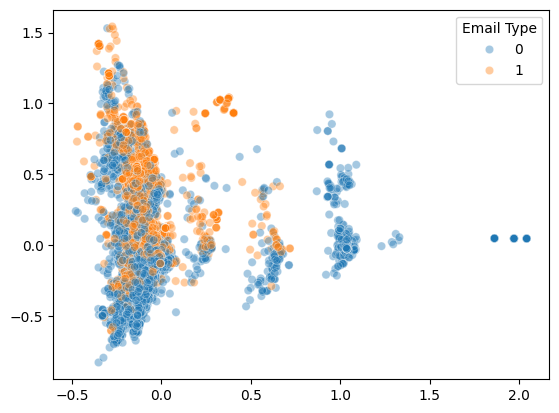

In [11]:
#Q3
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=y, alpha=0.4)

The phishing and safe emails partly separate. Phishing emails sit mostly in the upper part of the main cluster and safe emails sit lower. The separate groups on the right, at higher PC1, are almost all safe emails, probably a group of similar emails like newsletters or mailing lists. There’s still a lot of overlap.

In [12]:
#Q4
pca = PCA(n_components=2610).fit(X_train)
Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)
reg_pc = LinearRegression().fit(Z_train, y_train)
print(reg_pc.score(Z_train, y_train), reg_pc.score(Z_test, y_test))

0.7650509639569709 0.6718439815209292


Training R² is 0.765 and test R² is 0.672, almost the same as Q2 (0.766 and 0.670). The test score is very slightly higher because dropping about 100 low-variance components removes a little noise. Since 2,610 components keep nearly all the information, the two models are essentially equivalent.

#Q5
Many words appear together, which makes the regular regression unstable. Principal components fix this because they don’t overlap with each other. You can also keep just the most important components, which uses fewer features and reduces overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]